In [1]:
import sys
import os
sys.path.insert(1, '/home/sonndt/Projects/FFV_PINN')
import copy
import itertools
import os
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

from jaxpi.samplers import UniformSampler
from nc_porous.config import base_line_ffv  # File config chuẩn của bạn
from nc_porous.models import PorousNaturalConvection2D
from nc_porous.train import train_porous
from jaxpi.samplers import MeshSampler

def create_batches(config):
    H, L = float(config.physics.H), float(config.physics.L)
    scheme = getattr(config.diff, "scheme", "ad").lower().strip()

    if scheme in ["nd", "can", "ffv", "can_ffv", "ffv_continuous", "ffv_continous"]:
        n_x = config.diff.n_x
        n_y = config.diff.n_y

        dx = L / n_x
        dy = H / n_y

        assert jnp.isclose(dx, dy, atol=1e-6), (
            f"Sơ đồ {scheme.upper()} yêu cầu lưới vuông dx == dy, hiện tại dx={dx} != dy={dy}"
        )

        config.diff.h_stencil = dx #float(dx)

        # Cả can, ffv, ffv_continuous và can_ffv đều dùng tâm ô lân cận E, W, N, S -> reach = 1.0
        if scheme in ["can", "ffv", "can_ffv", "ffv_continuous", "ffv_continous"]:
            stencil_reach = 1.0
            num_exclude = 1
        else:  # "nd" (upwind bậc 2 vươn tới EE, WW, NN, SS)
            stencil_reach = 2.0
            num_exclude = 2

        use_continuous_mesh = getattr(config.diff, "use_continuous_mesh", False)

        if use_continuous_mesh:
            safe_x = stencil_reach * dx + 1e-4
            safe_y = stencil_reach * dy + 1e-4
            domain_safe = jnp.array([[safe_x, L - safe_x], [safe_y, H - safe_y]])
            sampler = UniformSampler(domain_safe, config.training.batch_size)
            if config.training.random_sampling:
                return sampler
            return itertools.repeat(next(iter(sampler)))

        else:
            num_pts_x = n_x - 2 * num_exclude
            num_pts_y = n_y - 2 * num_exclude

            assert num_pts_x > 0 and num_pts_y > 0, (
                f"Số lượng ô {n_x}x{n_y} quá ít so với stencil reach {stencil_reach}"
            )

            x_start = (num_exclude + 0.5) * dx
            x_end = L - (num_exclude + 0.5) * dx
            y_start = (num_exclude + 0.5) * dy
            y_end = H - (num_exclude + 0.5) * dy

            x_inner = jnp.linspace(x_start, x_end, num_pts_x)
            y_inner = jnp.linspace(y_start, y_end, num_pts_y)

            X, Y = jnp.meshgrid(x_inner, y_inner, indexing="ij")
            mesh_points = jnp.column_stack([X.ravel(), Y.ravel()])

            total_mesh_pts = mesh_points.shape[0]
            num_devices = jax.device_count()

            # QUAN TRỌNG: Nếu tổng số ô lưới <= batch_size, trả về TOÀN BỘ 100% điểm lưới
            # (cắt cho chia hết số GPU nếu cần) để tránh lỗi lấy mẫu trùng lặp bỏ sót 36.8% số ô của MeshSampler!
            if total_mesh_pts <= config.training.batch_size:
                usable_pts = (total_mesh_pts // num_devices) * num_devices
                return itertools.repeat(mesh_points[:usable_pts])
            else:
                sampler = MeshSampler(
                    mesh=mesh_points, batch_size=config.training.batch_size
                )
                if config.training.random_sampling:
                    return sampler
                return itertools.repeat(next(iter(sampler)))

    elif scheme == "ad":
        domain = jnp.array([[0.0, L], [0.0, H]])
        sampler = UniformSampler(domain, config.training.batch_size)
        if config.training.random_sampling:
            return sampler
        return itertools.repeat(next(iter(sampler)))
    else:
        raise ValueError(f"Sơ đồ diff.scheme='{scheme}' không được hỗ trợ.")



def run_ablation_experiment(exp_name, org_config, modify_config_fn=None):
    sub_config = copy.deepcopy(org_config.get_config())
    sub_config.wandb.name = f"{sub_config.wandb.name}_{exp_name}"

    if modify_config_fn is not None:
        sub_config = modify_config_fn(sub_config)

    batches = create_batches(sub_config)
    model, history = train_porous(config=sub_config, samplers=batches)
    return model, history

E1017 23:34:38.168691  119461 cuda_executor.cc:1182] [0] Failed to allocate device memory of 5.78GiB (6209667072 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
E1017 23:34:38.168762  119461 cuda_executor.cc:1182] [0] Failed to allocate device memory of 5.20GiB (5588700160 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
E1017 23:34:38.168816  119461 cuda_executor.cc:1182] [0] Failed to allocate device memory of 4.68GiB (5029830144 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
E1017 23:34:38.168869  119461 cuda_executor.cc:1182] [0] Failed to allocate device memory of 4.22GiB (4526846976 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
E1017 23:34:38.168927  119461 cuda_executor.cc:1182] [0] Failed to allocate device memory of 3.79GiB (4074162176 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
E1017 23:34:38.168998  119461 cuda_executor.cc:1182] [0] Failed to allocate device me

In [2]:

def wrapper_cfg(ra_val, diff_scheme, pts_enabled=False,use_continuous_mesh=False):    
    def modify_config(cfg):
        cfg.physics.Ra = ra_val
        cfg.diff.scheme = diff_scheme
        cfg.pseudo_time.enabled = pts_enabled
        cfg.diff.use_continuous_mesh = use_continuous_mesh
        return cfg
    return modify_config

model, history = run_ablation_experiment(
    exp_name="ra_1e6_ffv_can_pts_on_7",
    org_config=base_line_ffv,
    modify_config_fn=lambda cfg: wrapper_cfg(ra_val=1e6, diff_scheme="can_ffv", pts_enabled=True, use_continuous_mesh=True)(cfg)
)
# model, history = run_ablation_experiment(
#     exp_name="ra_1e6_ffv_pts_on_continuous_mesh",
#     modify_config_fn=lambda cfg: wrapper_cfg(ra_val=1e6, diff_scheme="ffv", pts_enabled=True, use_continuous_mesh=True)(cfg)
# )

# model, history = run_ablation_experiment(
#     exp_name="ra_1e6_ffv_pts_off_fixed_mesh",
#     modify_config_fn=lambda cfg: wrapper_cfg(ra_val=1e6, diff_scheme="ffv", pts_enabled=False)(cfg)
# )
# model, history = run_ablation_experiment(
#     exp_name="ra_1e6_ffv_pts_off_continuous_mesh",
#     modify_config_fn=lambda cfg: wrapper_cfg(ra_val=1e6, diff_scheme="ffv", pts_enabled=False, use_continuous_mesh=True)(cfg)
# )


Training PINN:   0%|          | 0/50000 [00:00<?, ?it/s]

Bắt đầu huấn luyện...
Step 00500 | Loss: 3.9171e-02 | T_dirichlet_bc: 6.140e-05 | T_neumann_bc: 7.274e-04 | T_res: 5.157e-03 | p_res: 2.850e-03 | u_bc: 4.980e-04 | u_res: 3.640e-03 | v_bc: 6.279e-04 | v_res: 1.442e-02 | tau_T: 2.61 | tau_p: 4.13 | tau_u: 5.99 | tau_v: 4.93 | Time/Log: 100.88s
Step 01000 | Loss: 1.8777e-02 | T_dirichlet_bc: 2.460e-05 | T_neumann_bc: 1.157e-04 | T_res: 2.783e-03 | p_res: 3.003e-03 | u_bc: 2.151e-04 | u_res: 1.637e-03 | v_bc: 4.381e-04 | v_res: 3.987e-03 | tau_T: 2.61 | tau_p: 4.13 | tau_u: 5.99 | tau_v: 4.93 | Time/Log: 11.57s
Step 01500 | Loss: 9.0496e-03 | T_dirichlet_bc: 2.685e-05 | T_neumann_bc: 1.394e-04 | T_res: 1.071e-03 | p_res: 9.745e-04 | u_bc: 1.983e-04 | u_res: 1.696e-03 | v_bc: 1.370e-04 | v_res: 1.731e-03 | tau_T: 3.04 | tau_p: 4.33 | tau_u: 5.89 | tau_v: 4.88 | Time/Log: 22.15s
Step 02000 | Loss: 2.3469e-02 | T_dirichlet_bc: 5.203e-05 | T_neumann_bc: 1.355e-04 | T_res: 2.702e-03 | p_res: 4.348e-03 | u_bc: 5.703e-04 | u_res: 3.035e-03 | v_b

In [3]:
import os
import pickle
import jaxpi

from jaxpi.checkpointing import create_checkpoint_manager, restore_checkpoint
from jaxpi.models import (
    create_arch,
    create_lr_schedule,
    create_optimizer,
    create_train_state,
)
from nc_porous.config import base_line_ffv
from nc_porous.models import PorousNaturalConvection2D


def load_saved_model(exp_name, step=None):
  """Nạp mô hình và history từ thư mục outputs.

  Args:
      exp_name: Tên thí nghiệm (ví dụ: 'With_PTS_Adaptive')
      step: Bước lặp cần load (int). Nếu None, tự động load bước mới nhất.
  """
  # 1. Tái tạo cấu hình khớp với thí nghiệm đã chạy
  config = base_line_ffv.get_config()
  config.wandb.name = f"{config.wandb.name}_{exp_name}"

  # 2. Khởi tạo train state rỗng theo cấu trúc mạng
  lr = create_lr_schedule(config.optim)
  tx = create_optimizer(config.optim, lr)
  arch = create_arch(config.arch)
  state = create_train_state(config, tx, arch)

  # 3. Khởi tạo đối tượng model
  model = PorousNaturalConvection2D(config, lr, tx, arch, state)

  # 4. Xác định đường dẫn checkpoint và nạp trọng số
  ckpt_dir = os.path.join(os.getcwd(), "outputs", config.wandb.name, "ckpt")
  ckpt_mngr = create_checkpoint_manager(config.saving, ckpt_dir)

  target_step = step if step is not None else ckpt_mngr.latest_step()
  if target_step is None:
    raise FileNotFoundError(
        f"Không tìm thấy checkpoint nào trong thư mục: {ckpt_dir}"
    )

  # Gán đè state đã phục hồi vào model
  model.state = restore_checkpoint(ckpt_mngr, model.state, step=target_step)
  print(f"-> Đã nạp thành công checkpoint tại step {int(model.state.step)}")

  # 5. Đọc lại file history.pkl (nếu có)
  history_path = os.path.join(
      os.getcwd(), "outputs", config.wandb.name, "history.pkl"
  )
  history = {}
  if os.path.exists(history_path):
    with open(history_path, "rb") as f:
      history = pickle.load(f)
    print(f"-> Đã nạp lịch sử huấn luyện: {len(history.get('loss', []))} bước log")

  return model, history, config

In [4]:
model_ffv_pts_fixed_grid, history_ffv_pts_fixed_grid, config_ffv_pts_fixed_grid = load_saved_model("ra_1e6_ffv_can_pts_on_7",step=50000)
# model_ffv_fixed_grid, history_ffv_fixed_grid, config_ffv_fixed_grid = load_saved_model("ra_1e6_ffv_pts_off_fixed_mesh")
# model_ffv_pts_continuous_mesh, history_ffv_pts_continuous_mesh, config_ffv_pts_continuous_mesh = load_saved_model("ra_1e6_ffv_pts_on_continuous_mesh")
# model_ffv_continuous_mesh, history_ffv_continuous_mesh, config_ffv_continuous_mesh = load_saved_model("ra_1e6_ffv_pts_off_continuous_mesh")
model_ad_pts, history_ad_pts, config_ad_pts = load_saved_model("ra_1e6_diff_ad")

-> Đã nạp thành công checkpoint tại step 50000
-> Đã nạp lịch sử huấn luyện: 500 bước log
-> Đã nạp thành công checkpoint tại step 50000
-> Đã nạp lịch sử huấn luyện: 500 bước log


In [5]:
import jax


import jax
import jax.numpy as jnp

import jax
import jax.numpy as jnp

def compute_benchmark_metrics(model, Nx=101, Ny=101):
    """
    Tính toán đầy đủ các thông số chuẩn (Benchmark Metrics) đối lưu tự nhiên:
    Nu_vol, Nu_mid, Nu_hot, Nu_cold, u_max, v_max.
    """
    params = model.state.params
    L = float(getattr(model.config.physics, "L", 1.0))
    H = float(getattr(model.config.physics, "H", 1.0))
    Ra = 1e6#float(getattr(model.config.physics, "Ra", 1e6)) # Tránh hardcode khi quét sweep
    Pr = float(getattr(model.config.physics, "Pr", 0.71))
    scale_conv = jnp.sqrt(Pr * Ra)

    # 1. Tạo lưới 2D đều trên miền tính toán (Ưu tiên lưới lẻ để trúng tâm 0.5)
    x_lin = jnp.linspace(0.0, L, Nx)
    y_lin = jnp.linspace(0.0, H, Ny)
    X, Y = jnp.meshgrid(x_lin, y_lin, indexing="xy")
    
    # 2. Đánh giá trường u, v, p, T
    eval_fn = jax.vmap(model.neural_net, in_axes=(None, 0, 0))
    u_pred, v_pred, _, T_pred = eval_fn(params, X.ravel(), Y.ravel())
    
    U_grid = u_pred.reshape(Ny, Nx)
    V_grid = v_pred.reshape(Ny, Nx)
    T_grid = T_pred.reshape(Ny, Nx)

    # 3. Tính Nu_vol (Nusselt trung bình toàn miền)
    # Tích phân số 2D bằng công thức hình thang cho u * T
    uT_grid = U_grid * T_grid
    int_uT_y = jnp.trapezoid(uT_grid, y_lin, axis=0)
    int_uT_total = jnp.trapezoid(int_uT_y, x_lin, axis=0)
    
    Nu_vol = float(1.0 + (scale_conv / (L * H)) * float(int_uT_total))

    # 4. Tính Nu_mid (Mặt cắt chính giữa x = L / 2)
    mid_idx = Nx // 2
    x_mid = x_lin[mid_idx]
    
    # Đạo hàm riêng dT/dx tại mặt cắt x = L/2
    def get_T(x, y):
        return model.neural_net(params, x, y)[3]
    
    grad_T_x_fn = jax.vmap(jax.grad(get_T, argnums=0), in_axes=(None, 0))
    dT_dx_mid = grad_T_x_fn(x_mid, y_lin)
    
    q_x_mid = scale_conv * U_grid[:, mid_idx] * T_grid[:, mid_idx] - dT_dx_mid
    Nu_mid = float(jnp.trapezoid(q_x_mid, y_lin) / H)

    # 5. Tính Nu tại vách nóng (x=0) và vách lạnh (x=L)
    dT_dx_hot = grad_T_x_fn(0.0, y_lin)
    dT_dx_cold = grad_T_x_fn(L, y_lin)
    Nu_hot = float(jnp.trapezoid(-dT_dx_hot, y_lin) / H)
    Nu_cold = float(jnp.trapezoid(-dT_dx_cold, y_lin) / H)

    # 6. Vận tốc cực đại trên các trục trung tâm
    # v_max trên trục nằm ngang y = H / 2
    y_mid_idx = Ny // 2
    v_mid_plane = V_grid[y_mid_idx, :]
    v_max = float(jnp.max(jnp.abs(v_mid_plane)))

    # u_max trên trục thẳng đứng x = L / 2
    u_mid_plane = U_grid[:, mid_idx]
    u_max = float(jnp.max(jnp.abs(u_mid_plane)))

    # Sai số cân bằng năng lượng
    imbalance = float(abs(Nu_hot - Nu_cold) / abs(Nu_hot) * 100.0)

    return {
        "Nu_vol": Nu_vol,
        "Nu_mid": Nu_mid,
        "Nu_hot": Nu_hot,
        "Nu_cold": Nu_cold,
        "u_max": float(u_max * scale_conv),
        "v_max": float(v_max * scale_conv),
        "energy_imbalance": imbalance,
    }


models_to_benchmark = {
    "FFV_PTS_contiouns_Grid": model_ffv_pts_fixed_grid,
    # "FFV_PTS_Continuous_Mesh": model_ffv_pts_continuous_mesh,
    # "FFV_No_PTS_Fixed_Grid": model_ffv_fixed_grid,
    # "FFV_No_PTS_Continuous_Mesh": model_ffv_continuous_mesh,
    "AD_PTS": model_ad_pts,
}

benchmark_results = {}
for name, model in models_to_benchmark.items():
    benchmark_results[name] = compute_benchmark_metrics(model) 

for name, metrics in benchmark_results.items():
    print(f"Benchmark Metrics for {name}:")
    print(f"  Nu_vol = {metrics['Nu_vol']:.4f}")
    print(f"  Nu_mid = {metrics['Nu_mid']:.4f}")
    print(f"  Nu_hot = {metrics['Nu_hot']:.4f}")
    print(f"  Nu_cold = {metrics['Nu_cold']:.4f}")
    print(f"  u_max = {metrics['u_max']:.4f}")
    print(f"  v_max = {metrics['v_max']:.4f}")
    print(f"  Energy Imbalance = {metrics['energy_imbalance']:.2f}%")
    print("-" * 50)

# benchmark_can_0 = compute_benchmark_metrics(model_can_0)
# benchmark_can_1 = compute_benchmark_metrics(model_can_1)
# benchmark_can_2 = compute_benchmark_metrics(model_can_2)
# print(f"PTS diff CAN 0: Nu_hot = {benchmark_can_0['Nu_hot']:.4f}, Nu_cold = {benchmark_can_0['Nu_cold']:.4f}, Energy Imbalance = {benchmark_can_0['energy_imbalance']:.2f}%, u_max = {benchmark_can_0['u_max']:.4f}, v_max = {benchmark_can_0['v_max']:.4f}, Nu_vol = {benchmark_can_0['Nu_vol']:.4f}, Nu_mid = {benchmark_can_0['Nu_mid']:.4f}")
# print(f"PTS diff CAN 1: Nu_hot = {benchmark_can_1['Nu_hot']:.4f}, Nu_cold = {benchmark_can_1['Nu_cold']:.4f}, Energy Imbalance = {benchmark_can_1['energy_imbalance']:.2f}%, u_max = {benchmark_can_1['u_max']:.4f}, v_max = {benchmark_can_1['v_max']:.4f}, Nu_vol = {benchmark_can_1['Nu_vol']:.4f}, Nu_mid = {benchmark_can_1['Nu_mid']:.4f}")
# print(f"PTS diff CAN 2: Nu_hot = {benchmark_can_2['Nu_hot']:.4f}, Nu_cold = {benchmark_can_2['Nu_cold']:.4f}, Energy Imbalance = {benchmark_can_2['energy_imbalance']:.2f}%, u_max = {benchmark_can_2['u_max']:.4f}, v_max = {benchmark_can_2['v_max']:.4f}, Nu_vol = {benchmark_can_2['Nu_vol']:.4f}, Nu_mid = {benchmark_can_2['Nu_mid']:.4f}")

Benchmark Metrics for FFV_PTS_contiouns_Grid:
  Nu_vol = 8.7597
  Nu_mid = 8.7707
  Nu_hot = 8.8298
  Nu_cold = 8.8003
  u_max = 64.6386
  v_max = 219.2479
  Energy Imbalance = 0.33%
--------------------------------------------------
Benchmark Metrics for AD_PTS:
  Nu_vol = 8.8661
  Nu_mid = 8.8807
  Nu_hot = 8.8162
  Nu_cold = 8.7735
  u_max = 64.3475
  v_max = 219.7970
  Energy Imbalance = 0.48%
--------------------------------------------------


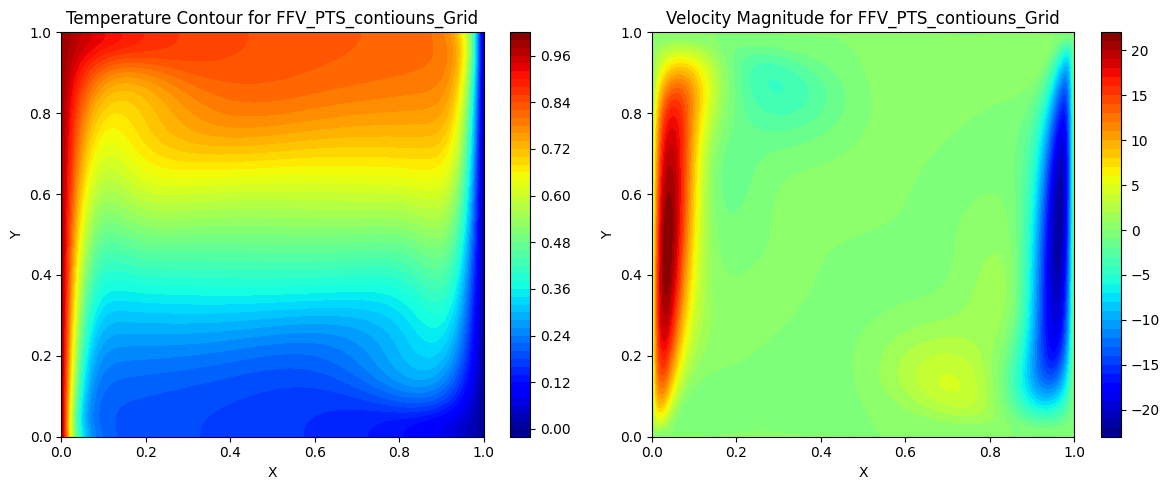

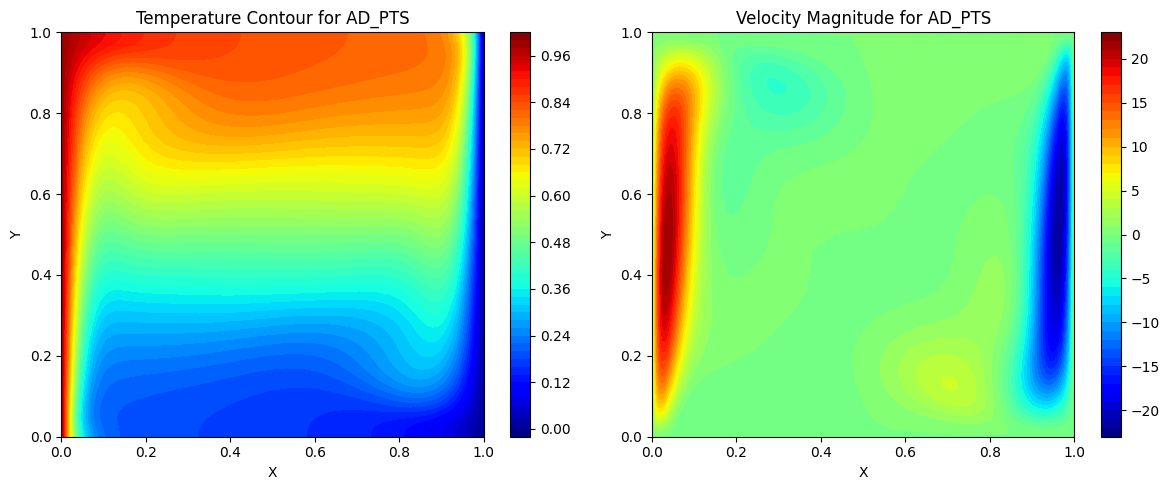

In [6]:
#plot temperature contours and velocity magnitude for each model
import matplotlib.pyplot as plt
import numpy as np

for name, model in models_to_benchmark.items():
    # Tạo lưới 2D đều trên miền tính toán
    Nx, Ny = 201, 201
    L = float(getattr(model.config.physics, "L", 1.0))
    H = float(getattr(model.config.physics, "H", 1.0))
    x_lin = jnp.linspace(0.0, L, Nx)
    y_lin = jnp.linspace(0.0, H, Ny)
    X, Y = jnp.meshgrid(x_lin, y_lin, indexing="xy")

    # Đánh giá trường T
    eval_fn = jax.vmap(model.neural_net, in_axes=(None, 0, 0))
    u, v, _, T_pred = eval_fn(model.state.params, X.ravel(), Y.ravel())
    scale_conv = jnp.sqrt(float(getattr(model.config.physics, "Pr", 0.71)) * float(getattr(model.config.physics, "Ra", 1e6)))
    u = u * scale_conv
    v = v * scale_conv
    u_mag = jnp.sqrt(u**2 + v**2).reshape(Ny, Nx)
    u_grid = u.reshape(Ny, Nx)
    v_grid = v.reshape(Ny, Nx)
    T_grid = T_pred.reshape(Ny, Nx)

    # Vẽ contour của nhiệt độ; them contourf line
    # Vẽ thêm u_mag
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    cp = plt.contourf(X, Y, T_grid, levels=50, cmap='jet')
    plt.colorbar(cp)
    plt.title(f'Temperature Contour for {name}')
    plt.xlabel('X')
    plt.ylabel('Y')

    plt.subplot(1, 2, 2)
    cp = plt.contourf(X, Y, v_grid, levels=50, cmap='jet')
    plt.colorbar(cp)
    plt.title(f'Velocity Magnitude for {name}')
    plt.xlabel('X')
    plt.ylabel('Y')

    plt.tight_layout()
    plt.show()

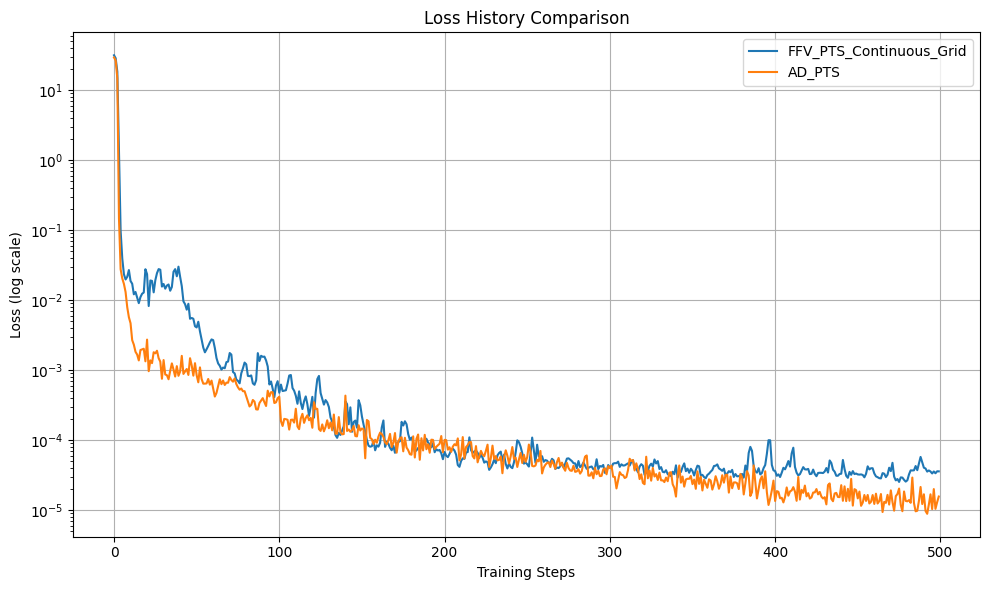

In [7]:
lost_results = {
    "FFV_PTS_Continuous_Grid": history_ffv_pts_fixed_grid.get("loss", []),
    # "FFV_PTS_Continuous_Mesh": history_ffv_pts_continuous_mesh.get("loss", []),
    # "FFV_No_PTS_Fixed_Grid": history_ffv_fixed_grid.get("loss", []),
    # "FFV_No_PTS_Continuous_Mesh": history_ffv_continuous_mesh.get("loss", []),
    "AD_PTS": history_ad_pts.get("loss", []),
}

#plot to compare loss history
plt.figure(figsize=(10, 6))
for name, loss_history in lost_results.items():
    plt.plot(loss_history, label=name)
plt.yscale("log")
plt.xlabel("Training Steps")
plt.ylabel("Loss (log scale)")
plt.title("Loss History Comparison")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("loss_history_comparison.png", dpi=300)
plt.show()

In [ ]:
model_ra1e2, hist_ra1e2, _ = load_saved_model("Ra_1e+02_ad")
behavior_ra1e2 = compute_benchmark_metrics(model_ra1e2)
print(f"PTS diff Ra1e2: Nu_hot = {behavior_ra1e2['Nu_hot']:.4f}, Nu_cold = {behavior_ra1e2['Nu_cold']:.4f}, Energy Imbalance = {behavior_ra1e2['energy_imbalance']:.2f}%, u_max = {behavior_ra1e2['u_max']:.4f}, v_max = {behavior_ra1e2['v_max']:.4f}, Nu_vol = {behavior_ra1e2['Nu_vol']:.4f}, Nu_mid = {behavior_ra1e2['Nu_mid']:.4f}")

model_ra1e3, hist_ra1e3, _ = load_saved_model("Ra_1e+03_ad")
behavior_ra1e3 = compute_benchmark_metrics(model_ra1e3)
print(f"PTS diff Ra1e3: Nu_hot = {behavior_ra1e3['Nu_hot']:.4f}, Nu_cold = {behavior_ra1e3['Nu_cold']:.4f}, Energy Imbalance = {behavior_ra1e3['energy_imbalance']:.2f}%, u_max = {behavior_ra1e3['u_max']:.4f}, v_max = {behavior_ra1e3['v_max']:.4f}, Nu_vol = {behavior_ra1e3['Nu_vol']:.4f}, Nu_mid = {behavior_ra1e3['Nu_mid']:.4f}")

model_ra1e4, hist_ra1e4, _ = load_saved_model("Ra_1e+04_ad")
behavior_ra1e4 = compute_benchmark_metrics(model_ra1e4)
print(f"PTS diff Ra1e4: Nu_hot = {behavior_ra1e4['Nu_hot']:.4f}, Nu_cold = {behavior_ra1e4['Nu_cold']:.4f}, Energy Imbalance = {behavior_ra1e4['energy_imbalance']:.2f}%, u_max = {behavior_ra1e4['u_max']:.4f}, v_max = {behavior_ra1e4['v_max']:.4f}, Nu_vol = {behavior_ra1e4['Nu_vol']:.4f}, Nu_mid = {behavior_ra1e4['Nu_mid']:.4f}")

model_ra1e5, hist_ra1e5, _ = load_saved_model("Ra_1e+05_ad")
behavior_ra1e5 = compute_benchmark_metrics(model_ra1e5)
print(f"PTS diff Ra1e5: Nu_hot = {behavior_ra1e5['Nu_hot']:.4f}, Nu_cold = {behavior_ra1e5['Nu_cold']:.4f}, Energy Imbalance = {behavior_ra1e5['energy_imbalance']:.2f}%, u_max = {behavior_ra1e5['u_max']:.4f}, v_max = {behavior_ra1e5['v_max']:.4f}, Nu_vol = {behavior_ra1e5['Nu_vol']:.4f}, Nu_mid = {behavior_ra1e5['Nu_mid']:.4f}")

model_ra1e6, hist_ra1e6, _ = load_saved_model("Ra_1e+06_ad")
behavior_ra1e6 = compute_benchmark_metrics(model_ra1e6)
print(f"PTS diff Ra1e6: Nu_hot = {behavior_ra1e6['Nu_hot']:.4f}, Nu_cold = {behavior_ra1e6['Nu_cold']:.4f}, Energy Imbalance = {behavior_ra1e6['energy_imbalance']:.2f}%, u_max = {behavior_ra1e6['u_max']:.4f}, v_max = {behavior_ra1e6['v_max']:.4f}, Nu_vol = {behavior_ra1e6['Nu_vol']:.4f}, Nu_mid = {behavior_ra1e6['Nu_mid']:.4f}")


<>:56: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:68: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:56: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:68: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/tmp/ipykernel_36007/1358544725.py:56: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  axs[1, 0].set_title('Velocity $|\mathbf{u}|$ & Streamlines (PTS)')
/tmp/ipykernel_36007/1358544725.py:68: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the fut

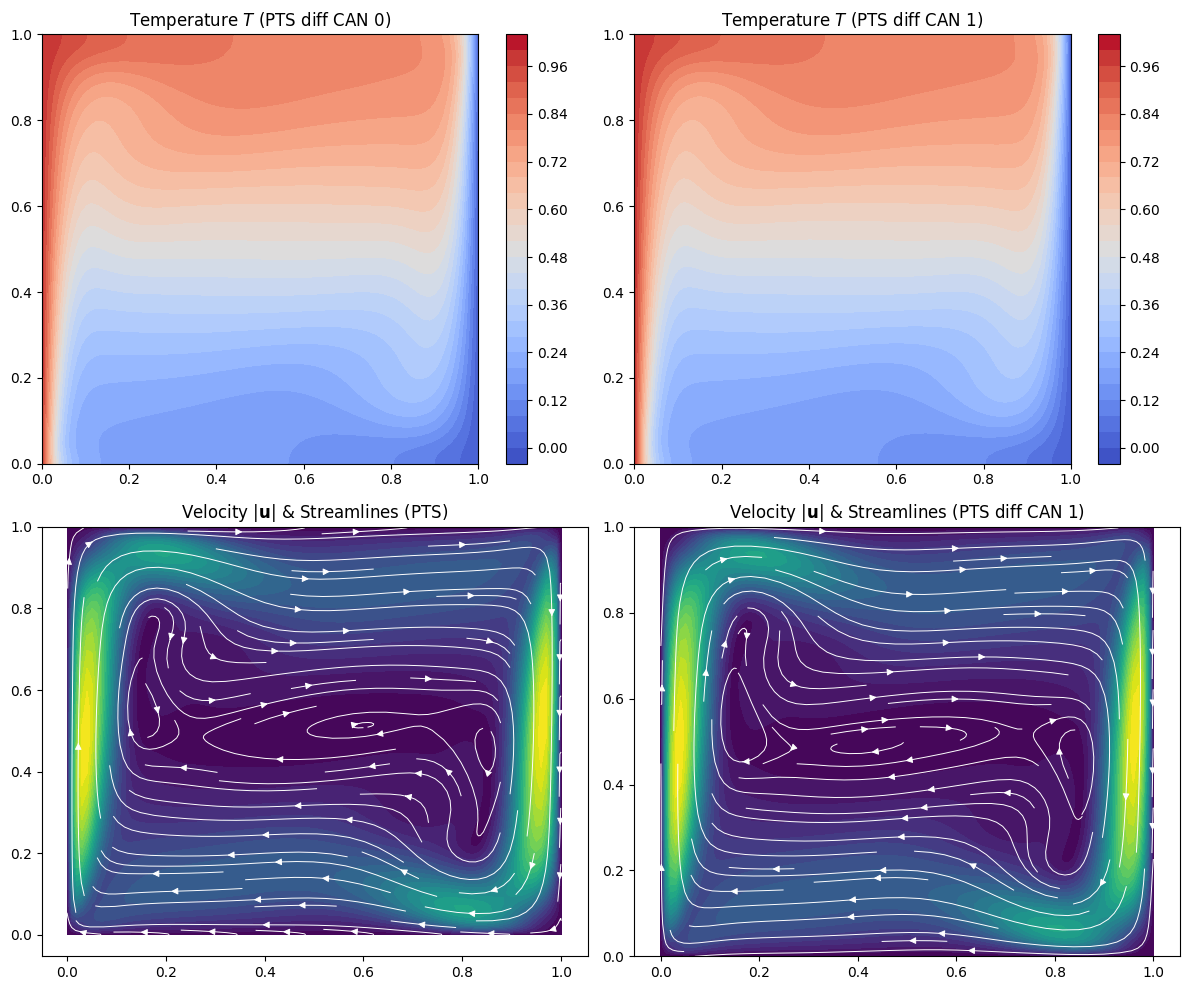

In [ ]:
import jax
import jax.numpy as jnp

# Tạo lưới đều 100x100 để nội suy trường nghiệm
Nx, Ny = 100, 100
x_lin = jnp.linspace(0.0, 1.0, Nx)
y_lin = jnp.linspace(0.0, 1.0, Ny)
X, Y = jnp.meshgrid(x_lin, y_lin)
x_flat, y_flat = X.ravel(), Y.ravel()
import numpy as np

def evaluate_fields(model):
  u, v, p, T = jax.vmap(model.neural_net, (None, 0, 0))(
      model.state.params, x_flat, y_flat
  )
  return (
      np.array(u).reshape(Ny, Nx),
      np.array(v).reshape(Ny, Nx),
      np.array(p).reshape(Ny, Nx),
      np.array(T).reshape(Ny, Nx),
  )


u_can_0, v_can_0, _, T_can_0 = evaluate_fields(model_ra1e2)
u_can_1, v_can_1, _, T_can_1 = evaluate_fields(model_ra1e6)


# Vẽ so sánh 3 mô hình
fig, axs = plt.subplots(2, 2, figsize=(12, 10))


# Đường đẳng nhiệt T (Isotherms)
im1 = axs[0, 0].contourf(X, Y, T_can_0, levels=25, cmap='jet')
axs[0, 0].set_title('Temperature $T$ (PTS diff CAN 0)')
plt.colorbar(im1, ax=axs[0, 0])

im2 = axs[0, 1].contourf(X, Y, T_can_1, levels=25, cmap='jet')
axs[0, 1].set_title('Temperature $T$ (PTS diff CAN 1)')
plt.colorbar(im2, ax=axs[0, 1])


# Độ lớn vận tốc & Đường dòng (Velocity Magnitude & Streamlines)
vel_mag_can_0 = np.sqrt(u_can_0**2 + v_can_0**2)
vel_mag_can_1 = np.sqrt(u_can_1**2 + v_can_1**2)

axs[1, 0].contourf(X, Y, vel_mag_can_0, levels=25, cmap='jet')
axs[1, 0].streamplot(
    np.array(x_lin),
    np.array(y_lin),
    u_can_0,
    v_can_0,
    color='white',
    density=1.0,
    linewidth=0.7,
)
axs[1, 0].set_title('Velocity $|\mathbf{u}|$ & Streamlines (PTS)')

axs[1, 1].contourf(X, Y, vel_mag_can_1, levels=50, cmap='jet')
axs[1, 1].streamplot(
    np.array(x_lin),
    np.array(y_lin),
    u_can_1,
    v_can_1,
    color='white',
    density=1.0,
    linewidth=0.7,
)
axs[1, 1].set_title('Velocity $|\mathbf{u}|$ & Streamlines (PTS diff CAN 1)')


plt.tight_layout()
plt.show()

In [8]:
import gc

def wrapper_cfg(ra_val, diff_scheme):    
    def modify_config(cfg):
        cfg.physics.Ra = ra_val
        cfg.diff.scheme = diff_scheme
        return cfg
    return modify_config

_ra = [1e2, 1e3, 1e4, 1e5, 1e6]
_scheme = ["ad", "can"]

for ra_val, diff_scheme in itertools.product(_ra, _scheme):
    exp_name = f"Ra_{ra_val:.0e}_{diff_scheme}"
    print(f"Running experiment: {exp_name}")
    modify_fn = wrapper_cfg(ra_val, diff_scheme)
    model, history = run_ablation_experiment(exp_name, modify_config_fn=modify_fn)
    del model, history
    gc.collect()

Running experiment: Ra_1e+02_ad


Training PINN:   0%|          | 0/50000 [00:00<?, ?it/s]

Bắt đầu huấn luyện...


KeyboardInterrupt: 